In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# ============================================================
# 2. LOAD DATA
# ============================================================

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"

train = pd.read_csv(DATA_DIR / "train.csv",index_col=0)
test = pd.read_csv(DATA_DIR / "test.csv",index_col=0)

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

Training shape: (103904, 24)
Testing shape: (25976, 24)


# <font color = "Orange"> 1. Initial inspection </font>

In [2]:
train.head()

,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


### Observations and Inquiries: Inconsistent capitalization across labels, need better understanding on number ranges (check data info from Kaggle), need to understand proportion of satisfied vs neutral/dissatisfied (class balance)

In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 24 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 103904 non-null  int64  
 1   Gender                             103904 non-null  str    
 2   Customer Type                      103904 non-null  str    
 3   Age                                103904 non-null  int64  
 4   Type of Travel                     103904 non-null  str    
 5   Class                              103904 non-null  str    
 6   Flight Distance                    103904 non-null  int64  
 7   Inflight wifi service              103904 non-null  int64  
 8   Departure/Arrival time convenient  103904 non-null  int64  
 9   Ease of Online booking             103904 non-null  int64  
 10  Gate location                      103904 non-null  int64  
 11  Food and drink                     103904 non-null

In [4]:
train.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,103904.0,NaN,NaN,NaN,64924.210502,37463.812252,1.0,32533.75,64856.5,97368.25,129880.0
Gender,103904,2,Female,52727,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Type,103904,2,Loyal Customer,84923,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,103904.0,NaN,NaN,NaN,39.379706,15.114964,7.0,27.0,40.0,51.0,85.0
Type of Travel,103904,2,Business travel,71655,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Class,103904,3,Business,49665,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flight Distance,103904.0,NaN,NaN,NaN,1189.448375,997.147281,31.0,414.0,843.0,1743.0,4983.0
Inflight wifi service,103904.0,NaN,NaN,NaN,2.729683,1.327829,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,103904.0,NaN,NaN,NaN,3.060296,1.525075,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,103904.0,NaN,NaN,NaN,2.756901,1.398929,0.0,2.0,3.0,4.0,5.0


In [5]:
train.columns.tolist()

['id',
 'Gender',
 'Customer Type',
 'Age',
 'Type of Travel',
 'Class',
 'Flight Distance',
 'Inflight wifi service',
 'Departure/Arrival time convenient',
 'Ease of Online booking',
 'Gate location',
 'Food and drink',
 'Online boarding',
 'Seat comfort',
 'Inflight entertainment',
 'On-board service',
 'Leg room service',
 'Baggage handling',
 'Checkin service',
 'Inflight service',
 'Cleanliness',
 'Departure Delay in Minutes',
 'Arrival Delay in Minutes',
 'satisfaction']

In [6]:
print("Duplicate rows:", train.duplicated().sum())
train.isnull().sum().sort_values(ascending=False)

Duplicate rows: 0


Arrival Delay in Minutes             310
id                                     0
Customer Type                          0
Gender                                 0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Age                                    0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Gate location                          0
Ease of Online booking                 0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
Food and drink                         0
On-board service                       0
Leg room service                       0
Checkin service                        0
Baggage handling                       0
Inflight service                       0
Cleanliness                            0
Departure Delay in Minutes             0
satisfaction                           0
dtype: int64

# <font color = "Orange"> 2. Variable Inspection </font>

## 2.1 Categorical columns

In [ ]:
categorical_cols = train.select_dtypes(include="str").columns

for col in categorical_cols:
    print(f"\n{col}")
    print(train[col].value_counts(dropna=False))
    



Gender
Gender
Female    52727
Male      51177
Name: count, dtype: int64

Customer Type
Customer Type
Loyal Customer       84923
disloyal Customer    18981
Name: count, dtype: int64

Type of Travel
Type of Travel
Business travel    71655
Personal Travel    32249
Name: count, dtype: int64

Class
Class
Business    49665
Eco         46745
Eco Plus     7494
Name: count, dtype: int64

satisfaction
satisfaction
neutral or dissatisfied    58879
satisfied                  45025
Name: count, dtype: int64


## 2.2 Numerical columns

In [8]:
numerical_cols = train.select_dtypes(include="number").columns
train[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
id,103904.0,64924.210502,37463.812252,1.0,32533.75,64856.5,97368.25,129880.0
Age,103904.0,39.379706,15.114964,7.0,27.00,40.0,51.00,85.0
Flight Distance,103904.0,1189.448375,997.147281,31.0,414.00,843.0,1743.00,4983.0
Inflight wifi service,103904.0,2.729683,1.327829,0.0,2.00,3.0,4.00,5.0
Departure/Arrival time convenient,103904.0,3.060296,1.525075,0.0,2.00,3.0,4.00,5.0
Ease of Online booking,103904.0,2.756901,1.398929,0.0,2.00,3.0,4.00,5.0
Gate location,103904.0,2.976883,1.277621,0.0,2.00,3.0,4.00,5.0
Food and drink,103904.0,3.202129,1.329533,0.0,2.00,3.0,4.00,5.0
Online boarding,103904.0,3.250375,1.349509,0.0,2.00,3.0,4.00,5.0
Seat comfort,103904.0,3.439396,1.319088,0.0,2.00,4.0,5.00,5.0


### Observation: Relatively centered age, right-skewed flight distance, right-skewed departure and arrival delay

### For delays: Not a lot of people experience delay, but when delays happen its substantial => Avoid removing them as might represent genuine disruptions

## 2.3 Check data range

In [9]:
rating_cols = [
    col for col in train.columns
    if col in [
        "Inflight wifi service",
        "Departure/Arrival time convenient",
        "Ease of Online booking",
        "Gate location",
        "Food and drink",
        "Online boarding",
        "Seat comfort",
        "Inflight entertainment",
        "On-board service",
        "Leg room service",
        "Baggage handling",
        "Checkin service",
        "Inflight service",
        "Cleanliness"
    ]
]

for col in rating_cols:
    print(f"{col}: {sorted(train[col].unique())}")

Inflight wifi service: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Departure/Arrival time convenient: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Ease of Online booking: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Gate location: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Food and drink: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Online boarding: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Seat comfort: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Inflight entertainment: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
On-board service: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Leg room service: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Baggag

## 2.4 Inspect missing arrival delays

In [10]:
missing_arrival = train[train["Arrival Delay in Minutes"].isna()]

missing_arrival.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,310.0,NaN,NaN,NaN,58836.183871,38026.713846,247.0,26121.75,50569.5,96631.75,129489.0
Gender,310,2,Male,159,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Type,310,2,Loyal Customer,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,310.0,NaN,NaN,NaN,39.125806,15.740626,7.0,27.0,39.0,51.0,72.0
Type of Travel,310,2,Business travel,190,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Class,310,3,Eco,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flight Distance,310.0,NaN,NaN,NaN,1230.609677,946.334977,77.0,459.75,945.0,1749.0,3981.0
Inflight wifi service,310.0,NaN,NaN,NaN,2.706452,1.317405,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,310.0,NaN,NaN,NaN,3.132258,1.472045,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,310.0,NaN,NaN,NaN,2.729032,1.399536,0.0,2.0,3.0,4.0,5.0


In [11]:
missing_arrival["Departure Delay in Minutes"].describe()

count    310.000000
mean      37.432258
std       62.239283
min        0.000000
25%        0.000000
50%        8.000000
75%       47.500000
max      455.000000
Name: Departure Delay in Minutes, dtype: float64

### Passengers with missing arrival delay experience higher departure delays and 182 out of 310 are neutral/classified

## 2.5 Target distribution

In [14]:
train["satisfaction"].value_counts(normalize=True) * 100


satisfaction
neutral or dissatisfied    56.666731
satisfied                  43.333269
Name: proportion, dtype: float64

<Axes: title={'center': 'Passenger Satisfaction Distribution'}, xlabel='Satisfaction', ylabel='Number of passengers'>

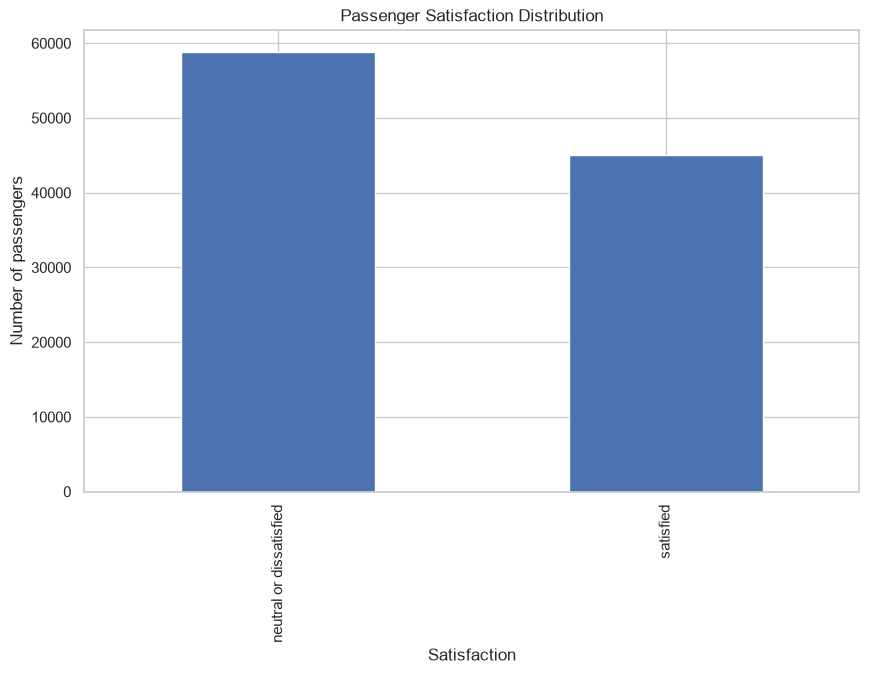

In [15]:
train["satisfaction"].value_counts().plot(
    kind="bar",
    title="Passenger Satisfaction Distribution",
    ylabel="Number of passengers",
    xlabel="Satisfaction"
)

# <font color = "Orange"> 3. Investigate relationships </font>

## 3.1 Satisfaction by passenger segment

In [16]:
segment_cols = [
    "Gender",
    "Customer Type",
    "Type of Travel",
    "Class"
]

for col in segment_cols:
    print(f"\n--- {col} ---")

    display(
        pd.crosstab(
            train[col],
            train["satisfaction"],
            normalize="index"
        ).mul(100).round(2)
    )


--- Gender ---


satisfaction,neutral or dissatisfied,satisfied
Gender,,
Female,57.26,42.74
Male,56.05,43.95



--- Customer Type ---


satisfaction,neutral or dissatisfied,satisfied
Customer Type,,
Loyal Customer,52.27,47.73
disloyal Customer,76.33,23.67



--- Type of Travel ---


satisfaction,neutral or dissatisfied,satisfied
Type of Travel,,
Business travel,41.74,58.26
Personal Travel,89.83,10.17



--- Class ---


satisfaction,neutral or dissatisfied,satisfied
Class,,
Business,30.57,69.43
Eco,81.39,18.61
Eco Plus,75.39,24.61


### Most substantial difference between neutral/dissatisfied vs satisfied in Customer type, Type of Travel, and Class

### Question: Are travel type and class independently associated with satisfaction, or are we observing overlapping patterns?

## 3.2 Average service ratings by satisfaction

In [17]:
rating_summary = (
    train.groupby("satisfaction")[rating_cols]
    .mean()
    .T
)

rating_summary["difference"] = (
    rating_summary["satisfied"]
    - rating_summary["neutral or dissatisfied"]
)

rating_summary.sort_values(
    "difference",
    ascending=False
).round(3)

satisfaction,neutral or dissatisfied,satisfied,difference
Online boarding,2.656,4.027,1.371
Inflight entertainment,2.894,3.965,1.071
Seat comfort,3.036,3.967,0.930
On-board service,3.019,3.857,0.838
Leg room service,2.991,3.822,0.831
Cleanliness,2.936,3.744,0.808
Inflight wifi service,2.400,3.161,0.762
Checkin service,3.043,3.646,0.603
Baggage handling,3.376,3.966,0.590
Inflight service,3.389,3.969,0.581


### Most notable difference in Online Boarding, Inflight entertainment, and Seat comfort satisfaction

## 3.3 Satisfaction and flight delays

In [18]:
delay_cols = [
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

train.groupby("satisfaction")[delay_cols].agg(
    ["mean", "median", "std"]
).round(2)

Departure Delay in Minutes                \
                                              mean median    std   
satisfaction                                                       
neutral or dissatisfied                      16.50    0.0  40.19   
satisfied                                    12.61    0.0  35.38   

                        Arrival Delay in Minutes                
                                            mean median    std  
satisfaction                                                    
neutral or dissatisfied                    17.13    0.0  40.56  
satisfied                                  12.63    0.0  35.96

## 3.4 Missingness and satisfaction

In [19]:
train["arrival_delay_missing"] = (
    train["Arrival Delay in Minutes"].isna()
)

pd.crosstab(
    train["arrival_delay_missing"],
    train["satisfaction"],
    normalize="index"
).mul(100).round(2)

satisfaction,neutral or dissatisfied,satisfied
arrival_delay_missing,,
False,56.66,43.34
True,58.71,41.29


### Higher neutral/dissatisfied in customers with missing arrival delay, but is it statistically significant?

# <font color = "Orange"> 4. Further relationship investigation and other analyses </font>

## 4.1 Travel type and class

In [20]:
pd.crosstab(
    train["Type of Travel"],
    train["Class"],
    normalize="index"
).mul(100).round(2)

Class,Business,Eco,Eco Plus
Type of Travel,,,
Business travel,66.30,28.27,5.43
Personal Travel,6.69,82.14,11.18


### Personal Travel - Eco + Eco Plus | Business Travel - Business + eco

### => Type of Travel clearly associated Flight Class => Cannot treat as indepedent variables => Need to use combination to explain satisfaction

## 4.2 How common are delays

In [21]:
delay_summary = pd.DataFrame({
    "Departure delayed (%)": (
        train["Departure Delay in Minutes"].gt(0).mean() * 100
    ),
    "Arrival delayed (%)": (
        train["Arrival Delay in Minutes"].gt(0).mean() * 100
    )
}, index=["All passengers"])

display(delay_summary.round(2))

,Departure delayed (%),Arrival delayed (%)
All passengers,43.54,43.73


In [ ]:
for col in [
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]:
    print(f"\n--- {col} ---")

    display(
        train.groupby("satisfaction")[col]
        .apply(lambda x: (x > 0).mean() * 100) # Only include passengers with flight delay
        .round(2)
    )


--- Departure Delay in Minutes ---


satisfaction
neutral or dissatisfied    45.95
satisfied                  40.38
Name: Departure Delay in Minutes, dtype: float64


--- Arrival Delay in Minutes ---


satisfaction
neutral or dissatisfied    47.61
satisfied                  38.65
Name: Arrival Delay in Minutes, dtype: float64

### Flight delays are more strongly associated with satisfaction than mean-delay comparison suggested (because it also included customers with no delays)

## 4.4 How often is Wifi rated Not Applicable

In [25]:
wifi_na = (
    train["Inflight wifi service"].eq(0)
    .groupby(train["satisfaction"])
    .mean()
    .mul(100)
)

display(wifi_na.round(2))

satisfaction
neutral or dissatisfied    0.01
satisfied                  6.87
Name: Inflight wifi service, dtype: float64

### A lot of zero's in Satisfied => Should correct them for comparisons with Wifi ratings

## 4.5 Satisfaction by travel type AND class

In [27]:
travel_class_satisfaction = pd.crosstab(
    [train["Type of Travel"], train["Class"]],
    train["satisfaction"],
    normalize="index"
).mul(100)

display(travel_class_satisfaction.round(2))

satisfaction              neutral or dissatisfied  satisfied
Type of Travel  Class                                       
Business travel Business                    27.98      72.02
                Eco                         70.38      29.62
                Eco Plus                    60.67      39.33
Personal Travel Business                    87.76      12.24
                Eco                         89.80      10.20
                Eco Plus                    91.29       8.71

### Business Travel - Business Class > Business Travel - Eco
### Not much difference between Personal Travel - Eco and Eco Plus
### Personal Travel - Eco Plus, lowest satisfied rate (lower than Personal Travel - Eco)

### But other aspects can affect too like passenger expectations => Should use statistical tests to characterize explicitly

## 4.6 Delay duration among delayed passengers only

In [28]:
delay_cols = [
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

for col in delay_cols:
    print(f"\n--- {col}: delayed passengers only ---")

    display(
        train.loc[train[col] > 0]
        .groupby("satisfaction")[col]
        .agg(["count", "mean", "median", "std"])
        .round(2)
    )


--- Departure Delay in Minutes: delayed passengers only ---


,count,mean,median,std
satisfaction,,,,
neutral or dissatisfied,27053,35.92,18.0,53.09
satisfied,18183,31.22,14.0,50.19



--- Arrival Delay in Minutes: delayed passengers only ---


,count,mean,median,std
satisfaction,,,,
neutral or dissatisfied,28035,35.86,18.0,52.66
satisfied,17400,32.59,15.0,51.83


### Neutral/disstatisfied passengers are more likely to experience delays, and the delays are slightly longer => Definitely an association

## 4.7 Wifi ratings excluding Not Applicable 

In [30]:
wifi_summary = (
    train.loc[train["Inflight wifi service"] > 0]
    .groupby("satisfaction")["Inflight wifi service"]
    .agg(["count", "mean", "median", "std"])
)

display(wifi_summary.round(3))

wifi_na_summary = (
    train.groupby("satisfaction")["Inflight wifi service"]
    .agg(
        total="count",
        not_applicable=lambda x: (x == 0).sum()
    )
)

wifi_na_summary["not_applicable_pct"] = (
    wifi_na_summary["not_applicable"]
    / wifi_na_summary["total"] * 100
)

display(wifi_na_summary.round(2))

,count,mean,median,std
satisfaction,,,,
neutral or dissatisfied,58871,2.400,2.0,0.964
satisfied,41930,3.395,4.0,1.385


,total,not_applicable,not_applicable_pct
satisfaction,,,
neutral or dissatisfied,58879,8,0.01
satisfied,45025,3095,6.87


### Difference in ratings even higher now excluding NA => When applicable, satisfied customers report substantially better wifi experiences.

# <font color ="Red">  Descriptive analyses regarding importance to Satisfaction conclusions:</font>
### Gender: Low
### Customer type: High
### Travel type: High
### Class: High
### Online boarding: Very High
### Inflight entertainment: High
### Wifi: High
### Flight delays: Medium
### Gate location: Low

# <font color = "Orange"> 5. Statistical Analysis </font>

### Flight delays are not normally distributed => Cannot use t-test
### Delays: User chi-square to see if its association with satisfaction, use Mann-whitney u to see if delay-duration distributions differ between satisfaction groups
### Other relationships can be inspected with chi-square of independence

## <font color = "Orange"> 5.1 Categorical variables - Chi-square test of independence </font>

In [50]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

train["Departure Delayed"] = (
    train["Departure Delay in Minutes"] > 0
)

train["Arrival Delayed"] = np.where(
    train["Arrival Delay in Minutes"].isna(),
    np.nan,
    train["Arrival Delay in Minutes"] > 0
)

# Categorical variables previously tested
categorical_columns = [
    "Customer Type",
    "Type of Travel",
    "Class",
    "Gender",
    "Departure Delayed",
    "Arrival Delayed"
]

chi_results = []

for column in categorical_columns:

    contingency_table = pd.crosstab(
        train[column],
        train["satisfaction"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    n = contingency_table.to_numpy().sum()

    # Cramér's V
    min_dimension = min(contingency_table.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * min_dimension))

    chi_results.append({
        "Variable": column,
        "Chi-square": chi2,
        "Degrees of freedom": dof,
        "P-value": p_value,
        "Cramér's V": cramers_v
    })

chi_results = pd.DataFrame(chi_results)

# Holm correction
chi_results["P-value Holm"] = multipletests(
    chi_results["P-value"],
    method="holm"
)[1]

display(chi_results.round(6))

,Variable,Chi-square,Degrees of freedom,P-value,Cramér's V,P-value Holm
0,Customer Type,3657.280805,1,0.000000,0.187613,0.000000
1,Type of Travel,20945.233826,1,0.000000,0.448979,0.000000
2,Class,26471.862944,2,0.000000,0.504750,0.000000
3,Gender,15.444417,1,0.000085,0.012192,0.000085
4,Departure Delayed,320.923381,1,0.000000,0.055576,0.000000
5,Arrival Delayed,837.756741,1,0.000000,0.089927,0.000000


## <font color = "Aquamarine"> Cramer's V from chi-square tests (All statistically significant): </font>
### Class — 0.505



### Type of Travel — 0.449



### Customer Type — 0.188



### Arrival Delayed — 0.090



### Departure Delayed — 0.056



### Gender — 0.012

### => Statistically significant does not establish practical importannce

## <font color = "Orange"> 5.2 Numerical and ordinal variables - Mann-Whitney U </font>

In [45]:
service_columns = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Inflight service",
    "Cleanliness"
]

print(train[service_columns].describe().round(2).T)

                                      count  mean   std  min  25%  50%  75%  \
Inflight wifi service              103904.0  2.73  1.33  0.0  2.0  3.0  4.0   
Departure/Arrival time convenient  103904.0  3.06  1.53  0.0  2.0  3.0  4.0   
Ease of Online booking             103904.0  2.76  1.40  0.0  2.0  3.0  4.0   
Gate location                      103904.0  2.98  1.28  0.0  2.0  3.0  4.0   
Food and drink                     103904.0  3.20  1.33  0.0  2.0  3.0  4.0   
Online boarding                    103904.0  3.25  1.35  0.0  2.0  3.0  4.0   
Seat comfort                       103904.0  3.44  1.32  0.0  2.0  4.0  5.0   
Inflight entertainment             103904.0  3.36  1.33  0.0  2.0  4.0  4.0   
On-board service                   103904.0  3.38  1.29  0.0  2.0  4.0  4.0   
Leg room service                   103904.0  3.35  1.32  0.0  2.0  4.0  4.0   
Baggage handling                   103904.0  3.63  1.18  1.0  3.0  4.0  5.0   
Checkin service                    103904.0  3.30  1

In [ ]:
from scipy.stats import mannwhitneyu

results = []

for column in service_columns:

    group_a = train.loc[
        train["satisfaction"] == "neutral or dissatisfied",
        column
    ]

    group_b = train.loc[
        train["satisfaction"] == "satisfied",
        column
    ]

    # Wi-Fi rating 0 means Not Applicable
    if column == "Inflight wifi service":
        group_a = group_a[group_a > 0]
        group_b = group_b[group_b > 0]

    # Mann-Whitney U test
    U, p_value = mannwhitneyu(
        group_a,
        group_b,
        alternative="two-sided"
    )

    # Rank-biserial correlation
    n_a = len(group_a)
    n_b = len(group_b)

    r_rb = 1 - (2 * U) / (n_a * n_b)

    results.append({
        "Variable": column,
        "Median (Neutral/Dissatisfied)": group_a.median(),
        "IQR (Neutral/Dissatisfied)": (
            group_a.quantile(0.75) - group_a.quantile(0.25)
        ),
        "Median (Satisfied)": group_b.median(),
        "IQR (Satisfied)": (
            group_b.quantile(0.75) - group_b.quantile(0.25)
        ),
        "U Statistic": U,
        "P-value": p_value,
        "Rank-biserial": r_rb
    })

mw_results = pd.DataFrame(results)

display(
    mw_results.sort_values(
        "Rank-biserial",
        ascending=False
    ).round(4)
)



,Variable,Median (Neutral/Dissatisfied),IQR (Neutral/Dissatisfied),Median (Satisfied),IQR (Satisfied),U Statistic,P-value,Rank-biserial
5,Online boarding,3.0,1.0,4.0,1.0,4.956884e+08,0.0000,0.6260
7,Inflight entertainment,3.0,2.0,4.0,1.0,7.241153e+08,0.0000,0.4537
0,Inflight wifi service,2.0,1.0,4.0,3.0,7.092655e+08,0.0000,0.4253
6,Seat comfort,3.0,2.0,4.0,1.0,7.818770e+08,0.0000,0.4101
8,On-board service,3.0,2.0,4.0,2.0,8.320988e+08,0.0000,0.3722
9,Leg room service,3.0,2.0,4.0,2.0,8.462022e+08,0.0000,0.3616
13,Cleanliness,3.0,2.0,4.0,2.0,8.681468e+08,0.0000,0.3450
10,Baggage handling,4.0,1.0,4.0,1.0,9.252544e+08,0.0000,0.3020
12,Inflight service,4.0,1.0,4.0,1.0,9.314924e+08,0.0000,0.2973
11,Checkin service,3.0,2.0,4.0,2.0,9.761286e+08,0.0000,0.2636


### Online boarding is the largest differentiator in ratings between satisfied and neutral/dissatisfied passengers

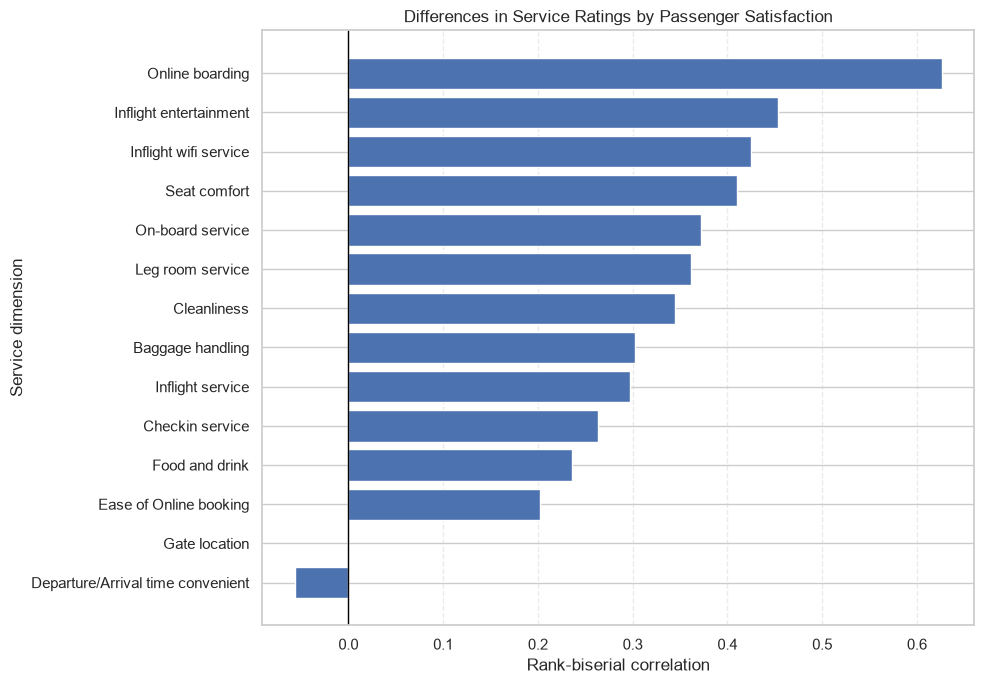

In [47]:
import matplotlib.pyplot as plt

# Sort by effect size
plot_data = mw_results.sort_values(
    "Rank-biserial",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    plot_data["Variable"],
    plot_data["Rank-biserial"]
)

# Reference line at zero
ax.axvline(0, linewidth=1, color="black")

ax.set_xlabel("Rank-biserial correlation")
ax.set_ylabel("Service dimension")
ax.set_title(
    "Differences in Service Ratings by Passenger Satisfaction"
)

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "../reports/figures/service_rating_rank_biserial.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## <font color = "Orange"> 5.3 In-group comparisons - Delay </font>

In [48]:
from scipy.stats import mannwhitneyu
import pandas as pd

delay_columns = [
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

delay_results = []

for column in delay_columns:

    # Only passengers who experienced a delay
    delayed = train[train[column] > 0]

    group_a = delayed.loc[
        delayed["satisfaction"] == "neutral or dissatisfied",
        column
    ]

    group_b = delayed.loc[
        delayed["satisfaction"] == "satisfied",
        column
    ]

    # Mann-Whitney U test
    U, p_value = mannwhitneyu(
        group_a,
        group_b,
        alternative="two-sided"
    )

    # Rank-biserial correlation
    r_rb = 1 - (2 * U) / (len(group_a) * len(group_b))

    delay_results.append({
        "Variable": column,
        "N (Neutral/Dissatisfied)": len(group_a),
        "Median (Neutral/Dissatisfied)": group_a.median(),
        "IQR (Neutral/Dissatisfied)": (
            group_a.quantile(0.75) - group_a.quantile(0.25)
        ),
        "N (Satisfied)": len(group_b),
        "Median (Satisfied)": group_b.median(),
        "IQR (Satisfied)": (
            group_b.quantile(0.75) - group_b.quantile(0.25)
        ),
        "U Statistic": U,
        "P-value": p_value,
        "Rank-biserial": r_rb
    })

delay_results_df = pd.DataFrame(delay_results)

display(delay_results_df.round(4))

,Variable,N (Neutral/Dissatisfied),Median (Neutral/Dissatisfied),IQR (Neutral/Dissatisfied),N (Satisfied),Median (Satisfied),IQR (Satisfied),U Statistic,P-value,Rank-biserial
0,Departure Delay in Minutes,27053,18.0,37.0,18183,14.0,31.0,267190578.0,0.0,-0.0864
1,Arrival Delay in Minutes,28035,18.0,35.0,17400,15.0,33.0,265217538.0,0.0,-0.0874


### Statistically significant but weak in magnitude

In [52]:
from statsmodels.stats.multitest import multipletests

# 1. Service-rating tests
mw_results["P-value Holm"] = multipletests(
    mw_results["P-value"],
    method="holm"
)[1]

# 2. Delay-duration tests
delay_results_df["P-value Holm"] = multipletests(
    delay_results_df["P-value"],
    method="holm"
)[1]



# Display adjusted results
display(
    mw_results[
        ["Variable", "P-value", "P-value Holm", "Rank-biserial"]
    ].round(6)
)

display(
    delay_results_df[
        ["Variable", "P-value", "P-value Holm", "Rank-biserial"]
    ].round(6)
)

display(chi_results.round(6))

,Variable,P-value,P-value Holm,Rank-biserial
0,Inflight wifi service,0.000000,0.000000,0.425338
1,Departure/Arrival time convenient,0.000000,0.000000,-0.056652
2,Ease of Online booking,0.000000,0.000000,0.202267
3,Gate location,0.964664,0.964664,-0.000156
4,Food and drink,0.000000,0.000000,0.236076
5,Online boarding,0.000000,0.000000,0.626040
6,Seat comfort,0.000000,0.000000,0.410133
7,Inflight entertainment,0.000000,0.000000,0.453710
8,On-board service,0.000000,0.000000,0.372244
9,Leg room service,0.000000,0.000000,0.361604


,Variable,P-value,P-value Holm,Rank-biserial
0,Departure Delay in Minutes,0.0,0.0,-0.086351
1,Arrival Delay in Minutes,0.0,0.0,-0.087383


,Variable,Chi-square,Degrees of freedom,P-value,Cramér's V,P-value Holm
0,Customer Type,3657.280805,1,0.000000,0.187613,0.000000
1,Type of Travel,20945.233826,1,0.000000,0.448979,0.000000
2,Class,26471.862944,2,0.000000,0.504750,0.000000
3,Gender,15.444417,1,0.000085,0.012192,0.000085
4,Departure Delayed,320.923381,1,0.000000,0.055576,0.000000
5,Arrival Delayed,837.756741,1,0.000000,0.089927,0.000000
